# First Passage Time Simulation

## Introduction

The goal of this Jupyter notebook is to create a faster, more accurate, and more versatile version of the first passage time simulation for various graphs from the paper

> **Vertex Centrality Reconstruction in an Inverse Problem for Information Diffusion**
> Yixian Gao, Songshuo Li, and Yang Yang (arXiv:2603.20710, 2026)

## Reconstruction (Python)

Reconstruction of the Section 5 simulation. Run the setup cell and the *Main functions* cells once, then run any experiment.

In [2]:
from functools import lru_cache

import matplotlib.pyplot as plt
import numpy as np
import torch

from graph import *

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
if device.type != "cuda":
    print("CUDA not available")

device: cpu
CUDA not available


## Experiment 1: a graph with eight vertices

Constant ground-truth $\mu$ (Section 5.1, Figure 1): a $2 \times 4$ ladder with $|B| = 3$, $|X\setminus B| = 5$, $w_{xy} = 0.25$, $\mu_x = 1$, $T = 9$. The observed vertices are the right three vertices of the top row. Paper FRNE: $0.248499\%$.

Check of Assumption 1 (ii): every vertex has degree $\le 3$, so $\sum_y w_{xy} \le 0.75 \le 1 = \mu_x$.

Change any value in the parameter cell to run a variant.

In [3]:
# ---- parameters (edit me) ----
grid1    = GridGraph.make_grid(2, 4)                      # 2 x 4 ladder, row 0 on top
B1_coord = [(0, 1), (0, 2), (1, 2)]             # observed vertices
w1       = 0.25                                 # edge weight
mu1_kind = "constant"                           # "constant", "deg", or an array of length |X|
mu1_val  = 1.0                                  # used when mu1_kind = "constant"
T1       = 9                                    # needs T >= |X|
N1       = 10**6                                # Monte Carlo walks per pair (x, y)
seed1    = 0

|X| = 8, |B| = 3, T = 9, t_max = 17


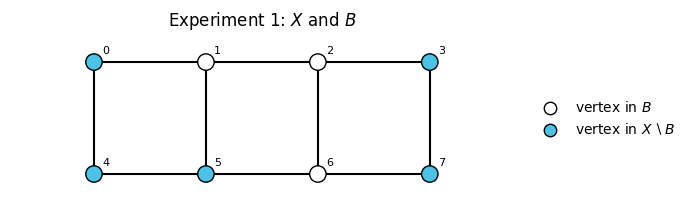

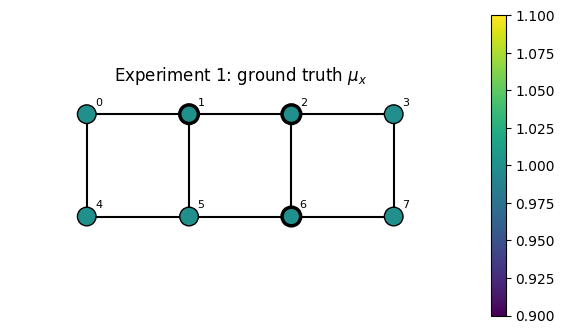

In [4]:
G1 = GridGraph(grid1, B1_coord, w=w1, mu=mu1_kind, mu_val=mu1_val)
W1, mu1, B1 = G1.W, G1.mu, G1.B
P1 = G1.transition_matrix()
t_max1 = 2 * T1 - 1                             # data needed for t = 1, ..., 2T-1
print(f"|X| = {len(mu1)}, |B| = {len(B1)}, T = {T1}, t_max = {t_max1}")

plot_graph(grid1, B1, title="Experiment 1: $X$ and $B$")
plot_graph(grid1, B1, values=mu1, title=r"Experiment 1: ground truth $\mu_x$")
plt.show()

In [5]:
r1_lit = exact_first_passage_literal(P1, B1, t_max1)
r1_emp = empirical_first_passage(P1, B1, t_max1, n_walks=N1, seed=seed1)

#summarize(P1, B1, r1_emp, r_lit=r1_lit, paper_frne=0.248499)

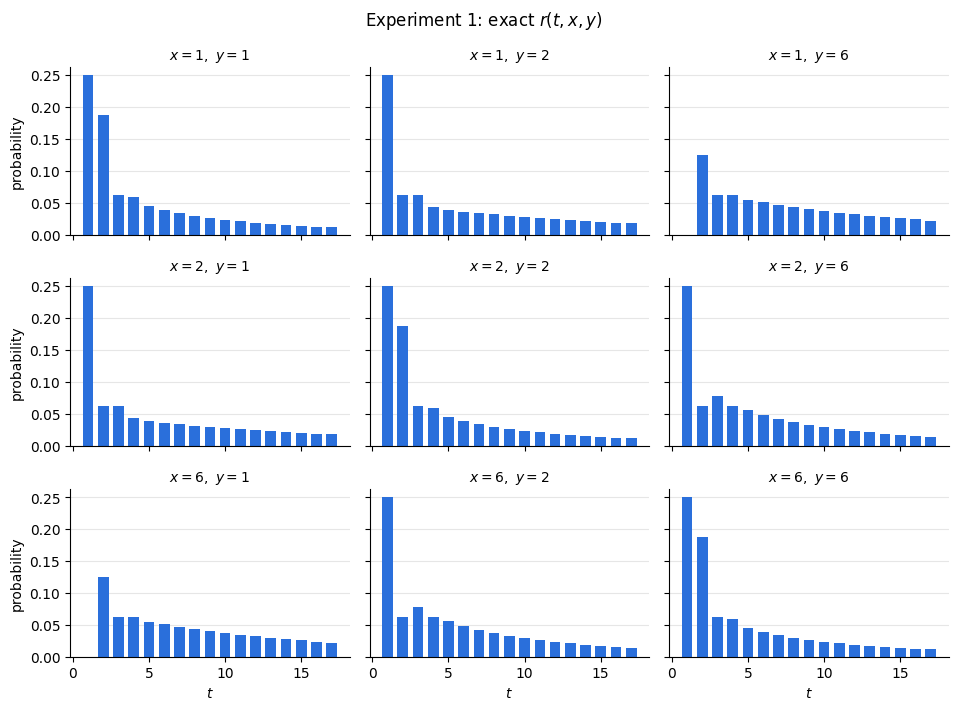

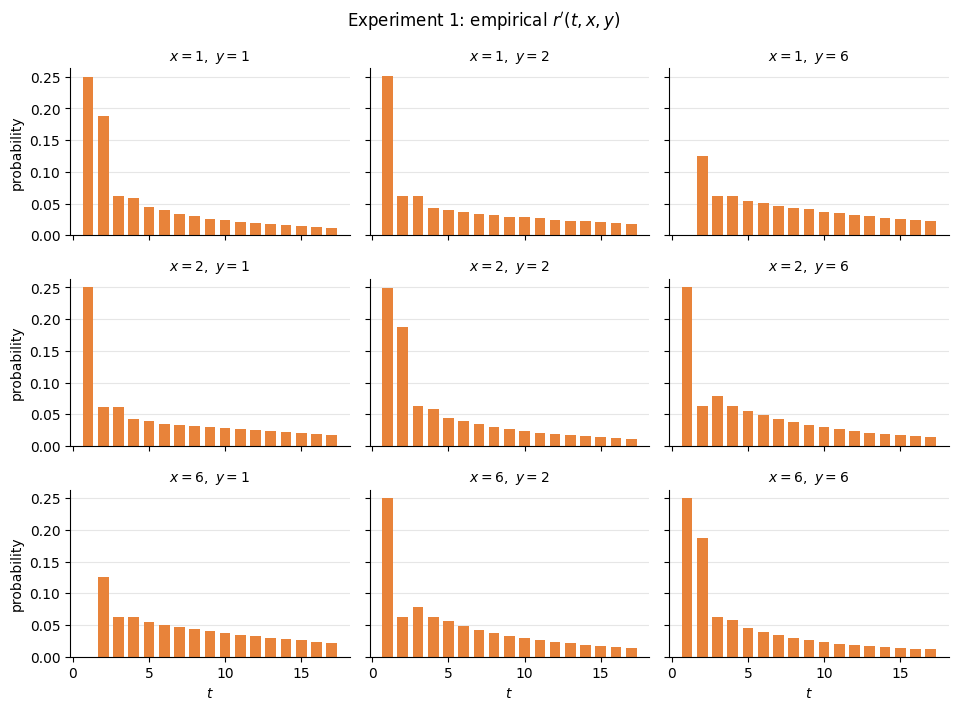

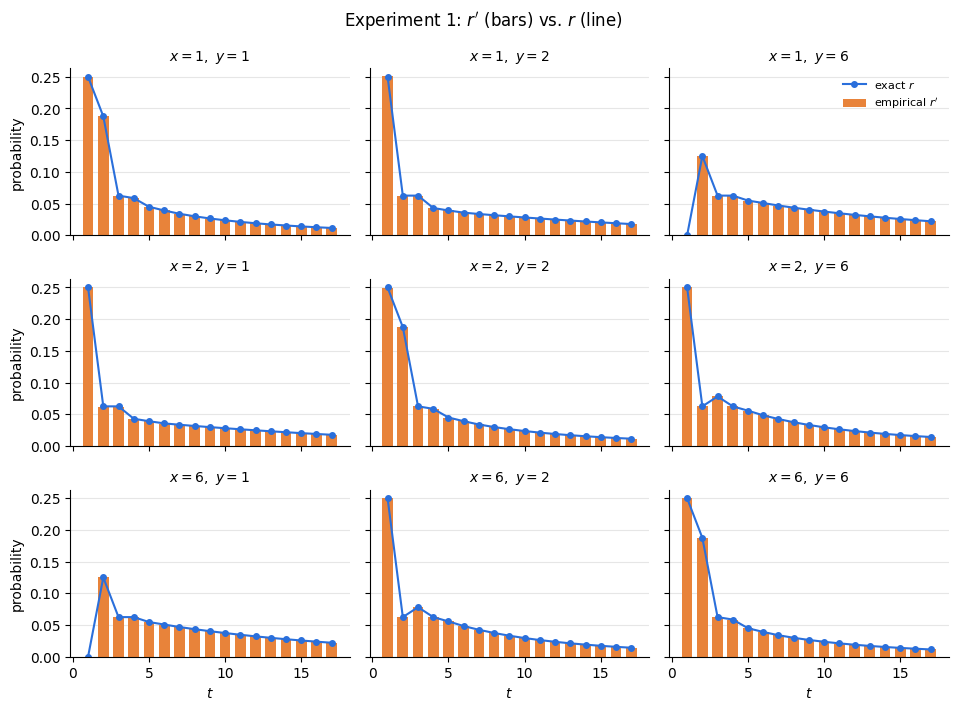

In [6]:
plot_exact_distribution(r1_lit, B1, title="Experiment 1: exact $r(t, x, y)$")
plot_empirical_distribution(r1_emp, B1, title="Experiment 1: empirical $r'(t, x, y)$")
plot_empirical_distribution(r1_emp, B1, r=r1_lit, title="Experiment 1: $r'$ (bars) vs. $r$ (line)")
plt.show()

### Experiment 1: all subsets of $B$

For every size $|B|=1,\ldots,7$, evaluate every possible subset of vertices (254 subsets total). The box plot shows the distribution of FRNE values for each size. The cell also reports the best subset at each size and the overall lowest-FRNE subset. These are Monte Carlo estimates; increase `N1_sweep` to reduce sampling noise, at the cost of a longer run.

In [ ]:
from itertools import combinations

N1_sweep = 10**4  # Monte Carlo walks per ordered pair, for each subset
B1_sweep_sizes = list(range(1, len(grid1)))
B1_sweep_frne = {nB: [] for nB in B1_sweep_sizes}
B1_sweep_results = []

for nB in B1_sweep_sizes:
    for vertex_indices in combinations(range(len(grid1)), nB):
        B_coords = [grid1[i] for i in vertex_indices]
        B_sweep = torch.tensor([G1.index[coord] for coord in B_coords], dtype=torch.long)
        r_exact = exact_first_passage_literal(P1, B_sweep, t_max1)
        subset_seed = seed1 + sum(1 << i for i in vertex_indices)
        r_empirical = empirical_first_passage(
            P1, B_sweep, t_max1, n_walks=N1_sweep,
            batch=min(10**4, N1_sweep), seed=subset_seed
        )
        subset_frne = frne(r_exact, r_empirical)
        B1_sweep_frne[nB].append(subset_frne)
        B1_sweep_results.append({
            "size": nB,
            "indices": vertex_indices,
            "vertices": tuple(B_coords),
            "frne": subset_frne,
        })

B1_best_by_size = {
    nB: min((result for result in B1_sweep_results if result["size"] == nB),
            key=lambda result: result["frne"])
    for nB in B1_sweep_sizes
}
B1_best_overall = min(B1_sweep_results, key=lambda result: result["frne"])

print(f"Evaluated {len(B1_sweep_results)} subsets.")
for nB, result in B1_best_by_size.items():
    print(f"|B|={nB}: best FRNE={result['frne']:.6f}%; "
          f"vertices={list(result['vertices'])}; indices={result['indices']}")
print("Overall best subset:", B1_best_overall)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.boxplot([B1_sweep_frne[nB] for nB in B1_sweep_sizes],
           positions=B1_sweep_sizes, showmeans=True)
ax.set_xticks(B1_sweep_sizes)
ax.set_xlabel(r"Number of observed vertices, $|B|$")
ax.set_ylabel("FRNE (%)")
ax.set_title("Experiment 1: FRNE across all subsets of each size")
ax.grid(axis="y", color="0.9")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()